# Hydropower Production & Revenue Analysis — Python

**Purpose:** continue the Power BI project with reproducible data preparation, exploratory analysis, correlation analysis, a time-ordered production model, and operational/revenue scenarios.

**Important data note:** the original spreadsheet/CSV was not attached to this conversation, so this notebook does **not** invent results or replace your project data. Export the same daily table used by Power BI as `hydropower_daily.csv` (or Excel) and place it next to this notebook. Then run the cells from top to bottom.

The Power BI screenshots suggest a Jan–Mar 2025 daily dataset and provide useful reconciliation checks:
- total production: about **73.84K MWh**
- average daily production: about **820.39 MWh**
- minimum daily production: about **490.92 MWh**
- maximum daily production: about **1.15K MWh**
- average electricity price: about **56.53 EUR/MWh**
- total revenue: about **4M EUR**

These are approximate visual readings from screenshots, not source data. Differences can occur because of rounding, filters, or measure definitions.

## 1. Install and import the tools

We use:
- **pandas** for loading and preparing tabular data;
- **matplotlib** for plots;
- **scikit-learn** for a baseline and a nonlinear regression model.

If needed, install the packages in a terminal with `pip install pandas numpy matplotlib scikit-learn openpyxl`.

In [8]:
# ==========================================
# HYDROPOWER PRODUCTION & REVENUE ANALYSIS
# Step 1: Import Python Libraries
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

# Visualization settings
sns.set_theme(style="whitegrid")

print("Hydropower Analysis Project")
print("Python libraries successfully imported!")


Hydropower Analysis Project
Python libraries successfully imported!


In [11]:
import os

print("Files currently available in Colab:")
print(os.listdir('/content'))

Files currently available in Colab:
['.config', 'HydropowerProductionAnalysis.xlsx', 'sample_data']


In [13]:
# Step 2: Load Hydropower Dataset

import pandas as pd

# Load Excel file
file_path = '/content/HydropowerProductionAnalysis.xlsx'

df = pd.read_excel(file_path)

# Display dataset information
print("Dataset successfully loaded!")

print("Dataset dimensions:", df.shape)

# Display first 5 rows
display(df.head())

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

Dataset successfully loaded!
Dataset dimensions: (95, 8)


,date,inflow_m3_s,turbine_flow_m3_s,net_head_m,turbine_efficiency_pct,electricity_price_eur_mwh,production_mwh,estimated_revenue_eur
0,2025-01-01 00:00:00,48.52,41.68,92.35,92.63,32.64,839.48,27397.80
1,2025-01-02 00:00:00,42.27,38.76,90.99,91.48,50.24,759.62,38160.94
2,2025-01-03 00:00:00,54.81,51.89,92.22,92.85,70.59,1046.24,73849.24
3,2025-01-04 00:00:00,47.47,41.76,90.90,92.55,66.76,827.26,55224.33
4,2025-01-05 00:00:00,51.82,43.73,95.32,91.31,64.32,896.07,57637.31



Column names:
['date', 'inflow_m3_s', 'turbine_flow_m3_s', 'net_head_m', 'turbine_efficiency_pct', 'electricity_price_eur_mwh', 'production_mwh', 'estimated_revenue_eur']


In [14]:
# Step 3: Data Quality Check

# Check dataset structure
print("DATASET INFORMATION")
df.info()

# Check missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# Check duplicate records
print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

# Statistical summary
print("\nSTATISTICAL SUMMARY")
display(df.describe().round(2))

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 95 entries, 0 to 94
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   date                       91 non-null     object 
 1   inflow_m3_s                90 non-null     float64
 2   turbine_flow_m3_s          90 non-null     float64
 3   net_head_m                 90 non-null     float64
 4   turbine_efficiency_pct     90 non-null     float64
 5   electricity_price_eur_mwh  90 non-null     float64
 6   production_mwh             90 non-null     float64
 7   estimated_revenue_eur      93 non-null     float64
dtypes: float64(7), object(1)
memory usage: 6.1+ KB

MISSING VALUES
date                         4
inflow_m3_s                  5
turbine_flow_m3_s            5
net_head_m                   5
turbine_efficiency_pct       5
electricity_price_eur_mwh    5
production_mwh               5
estimated_revenue_eur        2
dt

,inflow_m3_s,turbine_flow_m3_s,net_head_m,turbine_efficiency_pct,electricity_price_eur_mwh,production_mwh,estimated_revenue_eur
count,90.00,90.00,90.00,90.00,90.00,90.00,93.00
mean,48.03,41.95,90.90,91.49,56.53,820.39,89612.57
std,8.82,8.19,3.44,1.18,17.27,158.12,427765.12
min,29.98,25.06,84.76,88.42,12.00,490.92,0.00
25%,41.15,35.42,88.14,90.56,44.06,699.99,34208.67
50%,47.73,41.72,90.75,91.43,54.20,822.62,44962.51
75%,54.42,48.16,93.75,92.21,69.38,937.14,56721.37
max,66.53,58.00,97.36,94.99,92.38,1150.24,4166939.38


In [15]:
# Step 4: Investigate Missing Values and Duplicates

# 1. Display rows with missing values
print("ROWS WITH MISSING VALUES")

missing_rows = df[df.isnull().any(axis=1)]

display(missing_rows)

# 2. Display duplicate rows
print("DUPLICATE ROWS")

duplicates = df[df.duplicated(keep=False)]

display(duplicates)

# 3. Check date format
print("DATE COLUMN")

print(df['date'].head(10))

# 4. Check dataset size
print("Total rows with missing values:", len(missing_rows))
print("Total duplicate rows:", len(duplicates))


ROWS WITH MISSING VALUES


,date,inflow_m3_s,turbine_flow_m3_s,net_head_m,turbine_efficiency_pct,electricity_price_eur_mwh,production_mwh,estimated_revenue_eur
90,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
91,90,NaN,NaN,NaN,NaN,NaN,NaN,4166939.38
92,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
93,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00
94,NaN,NaN,NaN,NaN,NaN,NaN,NaN,90.00


DUPLICATE ROWS


,date,inflow_m3_s,turbine_flow_m3_s,net_head_m,turbine_efficiency_pct,electricity_price_eur_mwh,production_mwh,estimated_revenue_eur
90,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
92,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


DATE COLUMN
0    2025-01-01 00:00:00
1    2025-01-02 00:00:00
2    2025-01-03 00:00:00
3    2025-01-04 00:00:00
4    2025-01-05 00:00:00
5    2025-01-06 00:00:00
6    2025-01-07 00:00:00
7    2025-01-08 00:00:00
8    2025-01-09 00:00:00
9    2025-01-10 00:00:00
Name: date, dtype: object
Total rows with missing values: 5
Total duplicate rows: 2


In [16]:
# Keep all 91 daily observations
df_clean = df.iloc[:91].copy()

# Convert date column to datetime
df_clean['date'] = pd.to_datetime(df_clean['date'])

# Sort data chronologically
df_clean = df_clean.sort_values('date').reset_index(drop=True)

# Verify date range and dataset size
print("Number of daily observations:", len(df_clean))
print("First date:", df_clean['date'].min())
print("Last date:", df_clean['date'].max())

# Check the last 5 records
display(df_clean.tail())

Number of daily observations: 91
First date: 2025-01-01 00:00:00
Last date: 2025-03-31 00:00:00


,date,inflow_m3_s,turbine_flow_m3_s,net_head_m,turbine_efficiency_pct,electricity_price_eur_mwh,production_mwh,estimated_revenue_eur
86,2025-03-28,41.14,33.24,86.22,90.43,41.46,610.16,25294.49
87,2025-03-29,50.96,48.74,86.89,91.97,35.07,916.99,32157.24
88,2025-03-30,50.67,47.58,86.60,92.61,43.63,898.55,39201.40
89,2025-03-31,46.62,44.59,89.27,92.01,52.21,862.25,45020.65
90,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [17]:
# Keep only valid daily observations

df_clean = df_clean.dropna(subset=['date']).copy()

# Reset index
df_clean = df_clean.reset_index(drop=True)

# Verify dataset
print("Total daily observations:", len(df_clean))
print("First date:", df_clean['date'].min())
print("Last date:", df_clean['date'].max())
print("Missing dates:", df_clean['date'].isna().sum())

display(df_clean.tail())

Total daily observations: 90
First date: 2025-01-01 00:00:00
Last date: 2025-03-31 00:00:00
Missing dates: 0


,date,inflow_m3_s,turbine_flow_m3_s,net_head_m,turbine_efficiency_pct,electricity_price_eur_mwh,production_mwh,estimated_revenue_eur
85,2025-03-27,50.22,39.53,87.04,93.12,45.34,754.47,34208.67
86,2025-03-28,41.14,33.24,86.22,90.43,41.46,610.16,25294.49
87,2025-03-29,50.96,48.74,86.89,91.97,35.07,916.99,32157.24
88,2025-03-30,50.67,47.58,86.60,92.61,43.63,898.55,39201.40
89,2025-03-31,46.62,44.59,89.27,92.01,52.21,862.25,45020.65


In [18]:
# Step 6: Exploratory Data Analysis
# Descriptive Statistics

eda_columns = [
    'inflow_m3_s',
    'turbine_flow_m3_s',
    'net_head_m',
    'turbine_efficiency_pct',
    'electricity_price_eur_mwh',
    'production_mwh',
    'estimated_revenue_eur'
]

# Calculate descriptive statistics
eda_summary = df_clean[eda_columns].describe().T

# Display results
display(eda_summary.round(2))

,count,mean,std,min,25%,50%,75%,max
inflow_m3_s,90.00,48.03,8.82,29.98,41.15,47.73,54.42,66.53
turbine_flow_m3_s,90.00,41.95,8.19,25.06,35.42,41.72,48.16,58.00
net_head_m,90.00,90.90,3.44,84.76,88.14,90.75,93.75,97.36
turbine_efficiency_pct,90.00,91.49,1.18,88.42,90.56,91.43,92.21,94.99
electricity_price_eur_mwh,90.00,56.53,17.27,12.00,44.06,54.20,69.38,92.38
production_mwh,90.00,820.39,158.12,490.92,699.99,822.62,937.14,1150.24
estimated_revenue_eur,90.00,46299.33,16744.47,8546.53,34533.29,44991.58,56536.88,93427.80


# Step 6: Exploratory Data Analysis (EDA)

## 6.1 Descriptive Statistics

### Objective

The purpose of this stage is to examine the statistical characteristics of the hydropower dataset and understand the operating conditions of the hydropower plant during the period from January to March 2025.

Descriptive statistics help identify typical operating values, variations in performance, and the minimum and maximum values of key operational and financial indicators.

### Key Findings

**1. Water Inflow and Turbine Flow**

- Average water inflow was 48.03 m³/s.
- Average turbine flow was 41.95 m³/s.
- Average inflow exceeded average turbine flow, indicating a difference between water entering the system and water passing through the turbine.

**2. Net Head**

- Average net head was 90.90 metres.
- Values ranged from 84.76 to 97.36 metres.

**3. Turbine Efficiency**

- Average turbine efficiency was 91.49%.
- Efficiency ranged from 88.42% to 94.99%.
- The relatively narrow range suggests that turbine efficiency remained comparatively stable during the analysed period.

**4. Electricity Market Price**

- Average electricity price was 56.53 EUR/MWh.
- The minimum price was 12.00 EUR/MWh.
- The maximum price was 92.38 EUR/MWh.

This indicates considerable variation in electricity market prices.

**5. Electricity Production**

- Average daily production was 820.39 MWh.
- Minimum daily production was 490.92 MWh.
- Maximum daily production was 1,150.24 MWh.

**6. Estimated Revenue**

- Average daily revenue was 46,299.33 EUR.
- Minimum daily revenue was 8,546.53 EUR.
- Maximum daily revenue was 93,427.80 EUR.

### Analytical Interpretation

The descriptive analysis shows that hydropower production operated under varying hydrological and market conditions.

Turbine efficiency remained relatively stable, while water inflow and electricity prices showed considerable variation.

These observations provide a basis for further investigation of the relationships between water availability, turbine operation, electricity production, and revenue.

### Conclusion

Descriptive statistics provide an initial understanding of hydropower plant performance and establish a statistical baseline for the subsequent exploratory and predictive analysis.

The next stage examines daily production and revenue trends to identify changes and patterns over the analysed period.

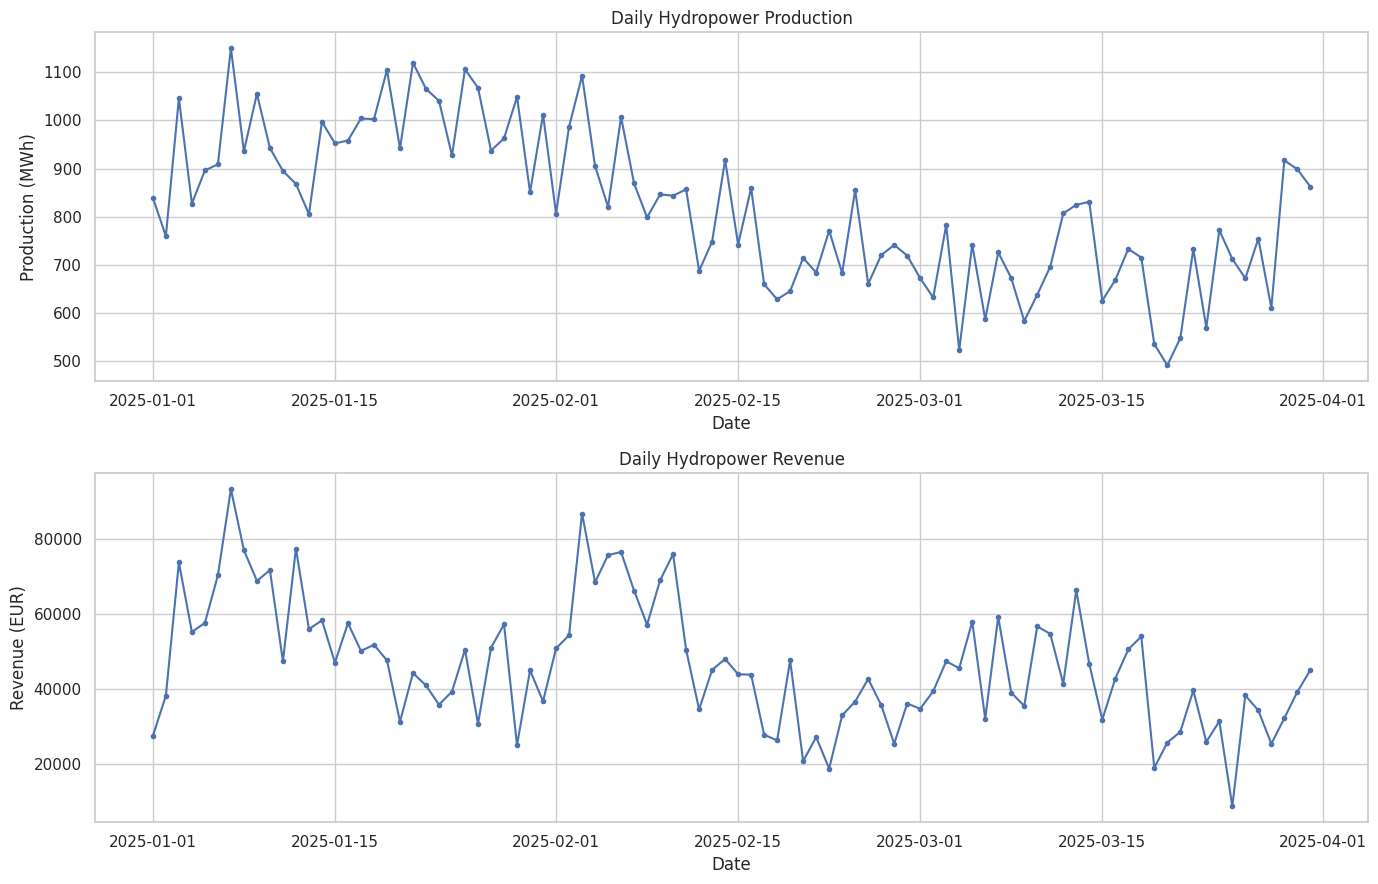

In [19]:
# Step 7: Production and Revenue Trends

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

# Daily Production
axes[0].plot(
    df_clean['date'],
    df_clean['production_mwh'],
    marker='o',
    markersize=3
)

axes[0].set_title('Daily Hydropower Production')
axes[0].set_ylabel('Production (MWh)')
axes[0].set_xlabel('Date')
axes[0].grid(True)

# Daily Revenue
axes[1].plot(
    df_clean['date'],
    df_clean['estimated_revenue_eur'],
    marker='o',
    markersize=3
)

axes[1].set_title('Daily Hydropower Revenue')
axes[1].set_ylabel('Revenue (EUR)')
axes[1].set_xlabel('Date')
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [20]:
# Step 8: Monthly Performance Analysis

# Create monthly summary
df_clean['month'] = df_clean['date'].dt.month_name()

monthly_summary = df_clean.groupby('month').agg(
    total_production_mwh=('production_mwh', 'sum'),
    total_revenue_eur=('estimated_revenue_eur', 'sum'),
    average_price_eur_mwh=('electricity_price_eur_mwh', 'mean'),
    average_efficiency_pct=('turbine_efficiency_pct', 'mean'),
    average_inflow_m3_s=('inflow_m3_s', 'mean')
)

# Set correct month order
month_order = ['January', 'February', 'March']

monthly_summary = monthly_summary.reindex(month_order)

# Display results
display(monthly_summary.round(2))

,total_production_mwh,total_revenue_eur,average_price_eur_mwh,average_efficiency_pct,average_inflow_m3_s
month,,,,,
January,30032.46,1614593.07,54.20,91.40,55.99
February,22270.08,1324477.11,58.31,91.72,47.07
March,21532.66,1227869.20,57.26,91.37,40.92


# Step 8: Monthly Performance Analysis

## 8.1 Monthly Operational and Financial Performance

### Objective

The objective of this analysis is to compare hydropower production, revenue, electricity prices, turbine efficiency, and water inflow across January, February, and March 2025.

Monthly aggregation helps identify changes in operational performance and financial results over the analysed period.

### Key Findings

**1. Monthly Electricity Production**

- January recorded the highest production at 30,032.46 MWh.
- February production decreased to 22,270.08 MWh.
- March production decreased further to 21,532.66 MWh.

Overall, production declined by approximately 28.3% between January and March.

**2. Monthly Revenue**

- January: EUR 1,614,593.07
- February: EUR 1,324,477.11
- March: EUR 1,227,869.20

Monthly revenue followed a downward trend, consistent with the reduction in electricity production.

**3. Electricity Market Price**

- January average price: 54.20 EUR/MWh.
- February average price: 58.31 EUR/MWh.
- March average price: 57.26 EUR/MWh.

Despite higher average electricity prices in February and March, revenue continued to decrease.

This suggests that the reduction in production volume outweighed the benefit of higher average market prices.

**4. Water Inflow**

Average water inflow decreased throughout the analysed period:

- January: 55.99 m³/s.
- February: 47.07 m³/s.
- March: 40.92 m³/s.

The declining water inflow coincided with the reduction in electricity production.

**5. Turbine Efficiency**

Average turbine efficiency remained relatively stable:

- January: 91.40%.
- February: 91.72%.
- March: 91.37%.

This indicates that the decline in production was not accompanied by a substantial change in average turbine efficiency.

### Analytical Interpretation

The monthly comparison reveals a consistent decline in water inflow, electricity production, and revenue between January and March 2025.

Although average electricity prices increased after January, this did not compensate for the lower production volumes.

Turbine efficiency remained relatively stable throughout the period.

The observed patterns suggest that hydrological conditions may have played an important role in production changes. However, further statistical analysis is required to investigate these relationships.

### Conclusion

January was the strongest month in terms of both electricity production and revenue.

The reduction in water inflow coinc

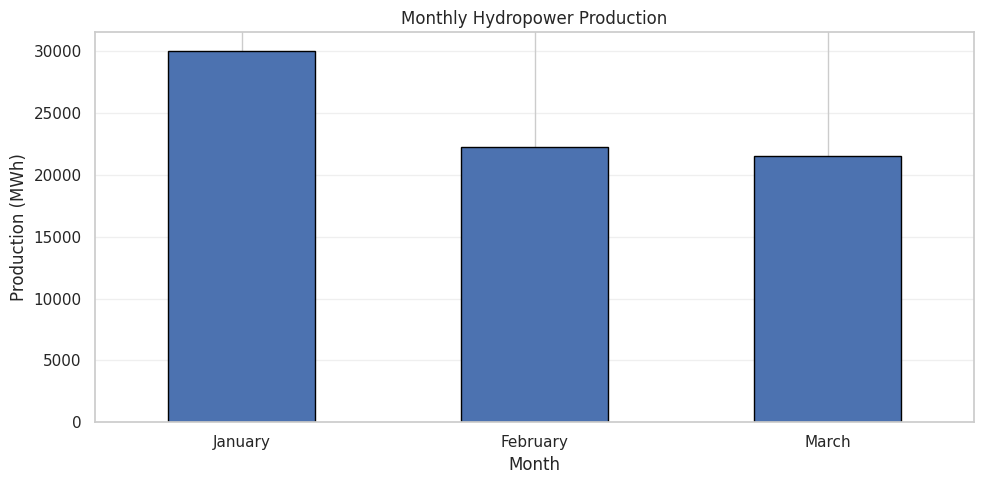

In [21]:
# Step 9: Monthly Production Comparison

plt.figure(figsize=(10, 5))

monthly_summary['total_production_mwh'].plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Monthly Hydropower Production')
plt.xlabel('Month')
plt.ylabel('Production (MWh)')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

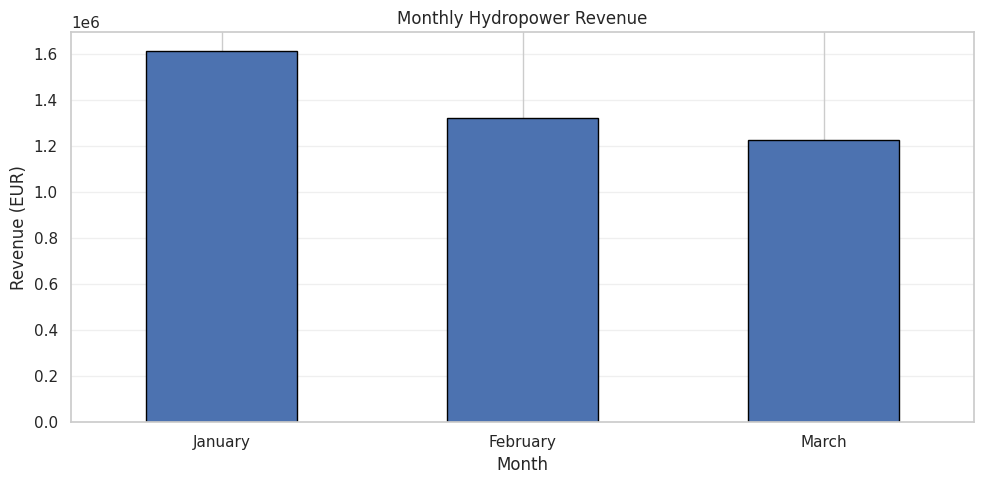

In [22]:
# Monthly Revenue Comparison

plt.figure(figsize=(10, 5))

monthly_summary['total_revenue_eur'].plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Monthly Hydropower Revenue')
plt.xlabel('Month')
plt.ylabel('Revenue (EUR)')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## Step 9: Production and Revenue Comparison

### Objective
This section compares monthly hydropower production and estimated revenue from January to March 2025 to identify changes in operational and financial performance.

### Key Findings

**1. Monthly Production**

January recorded the highest electricity production, at 30,032.46 MWh. Production decreased to 22,270.08 MWh in February and further declined to 21,532.66 MWh in March. Overall, production fell by approximately 28.3% between January and March.

**2. Monthly Revenue**

Revenue followed a similar downward trend. January generated €1,614,593.07, compared with €1,324,477.11 in February and €1,227,869.20 in March.

**3. Comparison of Production and Revenue**

Both charts show that January was the strongest month in terms of production and revenue. February and March recorded lower results. The decrease in revenue was consistent with the reduction in electricity production, although monthly electricity prices also influenced financial performance.

### Conclusion

The comparison indicates a decline in both hydropower production and estimated revenue during the first quarter of 2025. January demonstrated the strongest overall performance, while March recorded the lowest monthly production and revenue.

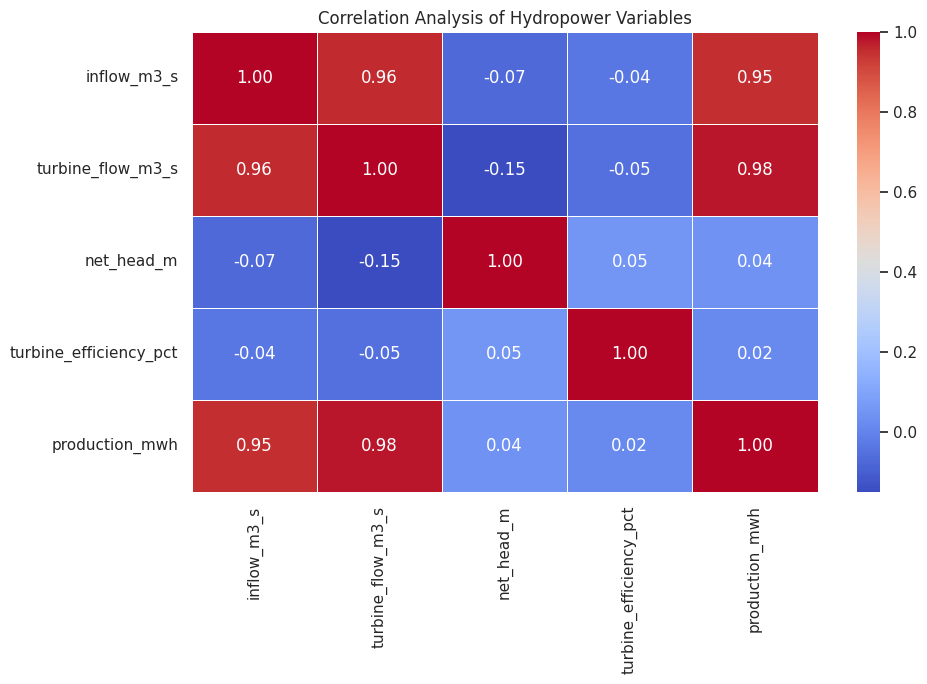

In [23]:
correlation_columns = [
    'inflow_m3_s',
    'turbine_flow_m3_s',
    'net_head_m',
    'turbine_efficiency_pct',
    'production_mwh'
]

correlation_matrix = df_clean[correlation_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Analysis of Hydropower Variables')
plt.tight_layout()
plt.show()

## Step 10: Correlation Analysis

### Objective
The purpose of this analysis is to examine the relationships between hydropower operational variables and electricity production using a correlation matrix.

### Key Findings

**1. Turbine Flow and Production**

Turbine flow has the strongest positive correlation with electricity production (0.98). This indicates that higher water flow through the turbine is strongly associated with higher electricity generation.

**2. Water Inflow and Production**

Water inflow also demonstrates a very strong positive correlation with production (0.95). This suggests that water availability is an important factor associated with hydropower output.

**3. Net Head and Production**

Net head has a very weak positive correlation with production (0.04). Within this dataset, no meaningful linear relationship is observed.

**4. Turbine Efficiency and Production**

Turbine efficiency has a correlation coefficient of 0.02 with production, indicating almost no linear correlation in the observed data.

**5. Relationship Between Water Inflow and Turbine Flow**

Water inflow and turbine flow have a strong positive correlation (0.96), suggesting that these two operational variables tend to change together.

### Conclusion

The correlation analysis identifies turbine flow and water inflow as the variables most strongly associated with electricity production. Net head and turbine efficiency show very weak linear correlations in this dataset.

Correlation does not establish causation. These findings will be used to guide the next stage of the analysis: predictive modelling of hydropower production.

# Step 11: Machine Learning – Hydropower Production Prediction

## 11.1 Objective

The objective of this stage is to develop a machine learning model that can predict daily hydropower electricity production based on operational data.

## 11.2 Machine Learning Method

For this project, we will use **Linear Regression**, a supervised machine learning algorithm. The model will learn the relationship between operational variables and electricity production using historical daily observations.

## 11.3 Input Features and Target Variable

The model will use the following operational variables as input features:

- **Water Inflow (`inflow_m3_s`)** – the volume of water entering the hydropower system.
- **Turbine Flow (`turbine_flow_m3_s`)** – the volume of water passing through the turbines.
- **Net Head (`net_head_m`)** – the effective water pressure head.
- **Turbine Efficiency (`turbine_efficiency_pct`)** – the operational efficiency of the turbine.

The target variable will be:

- **Electricity Production (`production_mwh`)** – the daily electricity generated, measured in megawatt-hours (MWh).

## 11.4 Expected Results

The purpose of the model is to:

1. Identify how well operational variables can predict daily electricity production.
2. Compare predicted production values with actual recorded values.
3. Evaluate model performance using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the R² score.
4. Assess whether Linear Regression provides a useful baseline for predicting hydropower production.

## 11.5 Model Evaluation

The dataset will be divided into training and testing sets. The model will be trained on historical observations and evaluated on data that was not used during training.

The final results will help us understand the predictive potential of the available operational data and the limitations of using a linear model for hydropower production forecasting.

## 11.6 Data Preparation and Train-Test Split

### Objective

The purpose of this stage is to prepare the dataset for machine learning and divide it into training and testing subsets.

### What We Will Analyse

We will use four operational variables as input features:

- Water inflow
- Turbine flow
- Net head
- Turbine efficiency

Daily electricity production will be used as the target variable that the model aims to predict.

### Train-Test Split

The dataset contains 90 daily observations. It will be divided chronologically into two subsets:

- **Training set (80%, 72 observations):** used to train the Linear Regression model.
- **Testing set (20%, 18 observations):** used to evaluate the model on observations not included in training.

A chronological split is applied to preserve the time order of the data. This allows us to train the model using earlier observations and test its predictive performance on later dates.

### Expected Outcome

At this stage, we expect to obtain two separate datasets ready for machine learning. This preparation will allow us to train the model and evaluate how accurately it predicts daily hydropower production.

In [24]:
# Define input features
X = df_clean[
    [
        'inflow_m3_s',
        'turbine_flow_m3_s',
        'net_head_m',
        'turbine_efficiency_pct'
    ]
]

# Define target variable
y = df_clean['production_mwh']

# Split data chronologically: 80% training, 20% testing
split_index = int(len(df_clean) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Display dataset information
print("Training set size:", len(X_train))
print("Testing set size:", len(X_test))

print("\nTraining period:")
print(df_clean['date'].iloc[0], "to", df_clean['date'].iloc[split_index - 1])

print("\nTesting period:")
print(df_clean['date'].iloc[split_index], "to", df_clean['date'].iloc[-1])

Training set size: 72
Testing set size: 18

Training period:
2025-01-01 00:00:00 to 2025-03-13 00:00:00

Testing period:
2025-03-14 00:00:00 to 2025-03-31 00:00:00


## 11.7 Model Training and Prediction

### Objective

The objective of this stage is to train a Linear Regression model using the prepared training dataset and generate predictions of daily hydropower electricity production.

### Model Training

The Linear Regression algorithm will be trained using four operational input features:

- Water inflow (`inflow_m3_s`)
- Turbine flow (`turbine_flow_m3_s`)
- Net head (`net_head_m`)
- Turbine efficiency (`turbine_efficiency_pct`)

The model will learn the relationships between these operational variables and daily electricity production.

### Production Prediction

After training, the model will be used to predict electricity production for the testing dataset, which contains 18 observations from March 14 to March 31, 2025.

The predicted production values will then be compared with the actual recorded production values for the same dates.

### Expected Outcome

This stage is expected to produce a comparison table containing:

- Date of observation
- Actual electricity production (MWh)
- Predicted electricity production (MWh)

The comparison will provide an initial understanding of how closely the model's predictions follow the actual hydropower production values.

The model's overall predictive performance will be evaluated in the next stage using statistical evaluation metrics.

In [25]:
# Initialize the Linear Regression model
model = LinearRegression()

# Train the model using the training dataset
model.fit(X_train, y_train)

# Generate predictions for the testing dataset
y_pred = model.predict(X_test)

# Create a comparison table
comparison = pd.DataFrame({
    'Date': df_clean['date'].iloc[split_index:].values,
    'Actual Production (MWh)': y_test.values,
    'Predicted Production (MWh)': y_pred
})

# Display the results
print("Model training completed successfully!")
print("\nActual vs Predicted Hydropower Production:")

display(comparison.round(2))

Model training completed successfully!

Actual vs Predicted Hydropower Production:


,Date,Actual Production (MWh),Predicted Production (MWh)
0,2025-03-14,830.87,826.71
1,2025-03-15,625.52,618.84
2,2025-03-16,668.37,654.43
3,2025-03-17,733.09,729.31
4,2025-03-18,715.10,704.03
5,2025-03-19,535.52,519.76
6,2025-03-20,490.92,474.11
7,2025-03-21,547.41,526.51
8,2025-03-22,732.79,723.37
9,2025-03-23,569.62,550.67


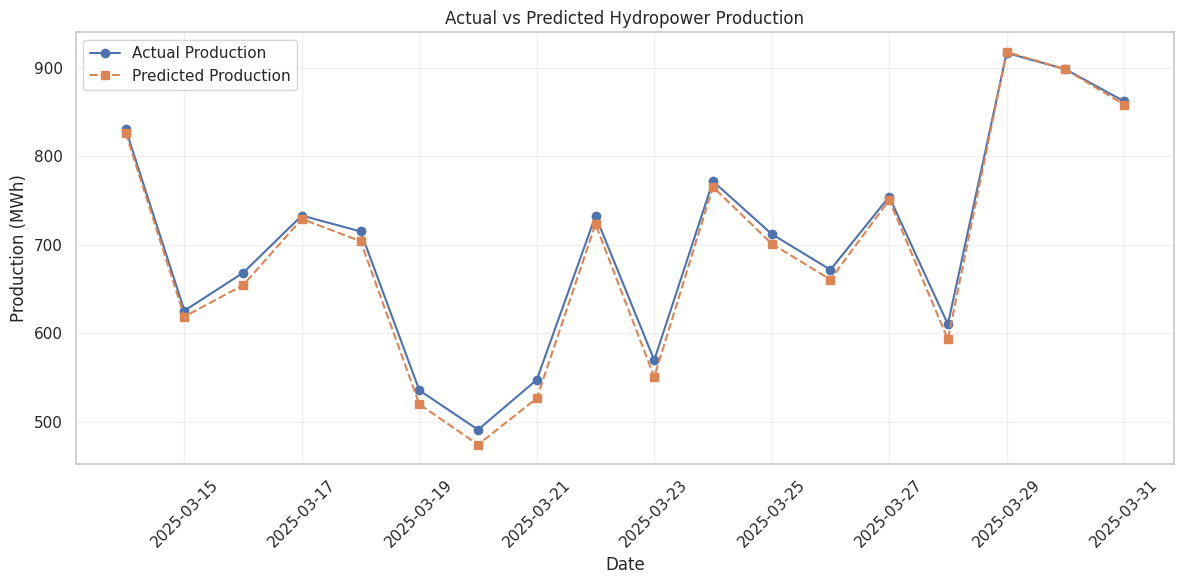

In [26]:
plt.figure(figsize=(12, 6))

plt.plot(
    comparison['Date'],
    comparison['Actual Production (MWh)'],
    marker='o',
    label='Actual Production'
)

plt.plot(
    comparison['Date'],
    comparison['Predicted Production (MWh)'],
    marker='s',
    linestyle='--',
    label='Predicted Production'
)

plt.title('Actual vs Predicted Hydropower Production')
plt.xlabel('Date')
plt.ylabel('Production (MWh)')
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 11.8 Model Evaluation

### Objective

The objective of this stage is to evaluate the predictive performance of the Linear Regression model and determine how accurately it estimates daily hydropower electricity production.

### Evaluation Metrics

To assess the model's performance, three evaluation metrics will be used:

**1. Mean Absolute Error (MAE)**

MAE measures the average absolute difference between actual and predicted production values. It indicates how far the model's predictions are from the actual values, on average, measured in MWh. Lower values indicate better predictive accuracy.

**2. Root Mean Squared Error (RMSE)**

RMSE measures the square root of the average squared prediction errors. It gives greater weight to larger errors and helps identify whether the model makes significant prediction mistakes. Lower values indicate better performance.

**3. Coefficient of Determination (R²)**

The R² score measures how well the model explains the variation in actual electricity production. A value closer to 1 indicates a stronger fit between predicted and actual values.

### Expected Outcome

The evaluation will provide a quantitative assessment of the Linear Regression model using the testing dataset, which contains 18 daily observations.

The results will help determine how accurately the model predicts hydropower production and whether Linear Regression is a suitable baseline forecasting method for this dataset.

The final interpretation will be based on the calculated evaluation metrics.

In [27]:
# Calculate model evaluation metrics
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

# Display evaluation results
print("Linear Regression Model Evaluation")
print("-----------------------------------")
print(f"Mean Absolute Error (MAE): {mae:.2f} MWh")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} MWh")
print(f"R-squared (R²): {r2:.4f}")

Linear Regression Model Evaluation
-----------------------------------
Mean Absolute Error (MAE): 9.76 MWh
Root Mean Squared Error (RMSE): 11.59 MWh
R-squared (R²): 0.9909


## 11.9 Interpretation of Model Evaluation Results

### Evaluation Results

The Linear Regression model achieved the following performance metrics on the testing dataset:

- **Mean Absolute Error (MAE): 9.76 MWh**
- **Root Mean Squared Error (RMSE): 11.59 MWh**
- **R-squared (R²): 0.9909**

### Key Findings

**1. Mean Absolute Error (MAE)**

The MAE of 9.76 MWh indicates that the model's predictions differ from the actual daily electricity production by approximately 9.76 MWh on average.

**2. Root Mean Squared Error (RMSE)**

The RMSE of 11.59 MWh indicates a relatively small prediction error. Its value is slightly higher than the MAE, suggesting that larger prediction errors have some influence on the overall error.

**3. R-squared (R²)**

The R² score of 0.9909 indicates that the model explains approximately 99.09% of the variation in electricity production within the testing dataset.

### Conclusion

The evaluation results demonstrate that the Linear Regression model achieved a very strong fit on the testing data. The low MAE and RMSE values, together with the high R² score, indicate that the model predicts daily hydropower production with high accuracy for the observed test period.

However, these results should be interpreted with caution because the dataset contains only 90 daily observations and the testing period covers 18 days. Further validation using a larger dataset and additional time periods would help assess the model's reliability for future forecasting.

# Step 12: Feature Importance – Linear Regression Coefficients

## 12.1 Objective

The objective of this stage is to examine the coefficients of the Linear Regression model and understand how different operational variables contribute to the prediction of hydropower electricity production.

## 12.2 Variables Analysis

The analysis will focus on four input features:

- **Water Inflow (`inflow_m3_s`)**
- **Turbine Flow (`turbine_flow_m3_s`)**
- **Net Head (`net_head_m`)**
- **Turbine Efficiency (`turbine_efficiency_pct`)**

## 12.3 Regression Coefficients

The coefficients of the Linear Regression model represent the estimated relationship between each input variable and predicted electricity production, while keeping the other input variables constant.

- A positive coefficient indicates a positive relationship with predicted production.
- A negative coefficient indicates a negative relationship with predicted production.
- A coefficient closer to zero indicates a smaller estimated linear effect per unit of the corresponding feature.

## 12.4 Expected Outcome

The purpose of this analysis is to:

1. Identify which operational variables have the largest regression coefficients.
2. Understand the direction of each variable's relationship with predicted electricity production.
3. Compare the model coefficients with the correlation analysis performed earlier.
4. Gain a better understanding of how the Linear Regression model generates its predictions.

## 12.5 Analytical Considerations

Regression coefficients should be interpreted carefully because the input variables have different measurement units and scales. In addition, water inflow and turbine flow are strongly correlated, which may affect the interpretation of their individual coefficients.

### Expected Result

This analysis will provide additional insight into the model's behaviour and help explain which operational factors contribute most strongly to its predictions.

In [28]:
# Extract regression coefficients
coefficients = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': model.coef_
})

# Display regression coefficients
coefficients = coefficients.sort_values(
    by='Coefficient',
    ascending=False
)

display(coefficients.round(4))

# Display the intercept
print("Model Intercept:", round(model.intercept_, 4))

,Feature,Coefficient
1,turbine_flow_m3_s,19.43
2,net_head_m,9.41
3,turbine_efficiency_pct,9.07
0,inflow_m3_s,0.37


Model Intercept: -1700.3275


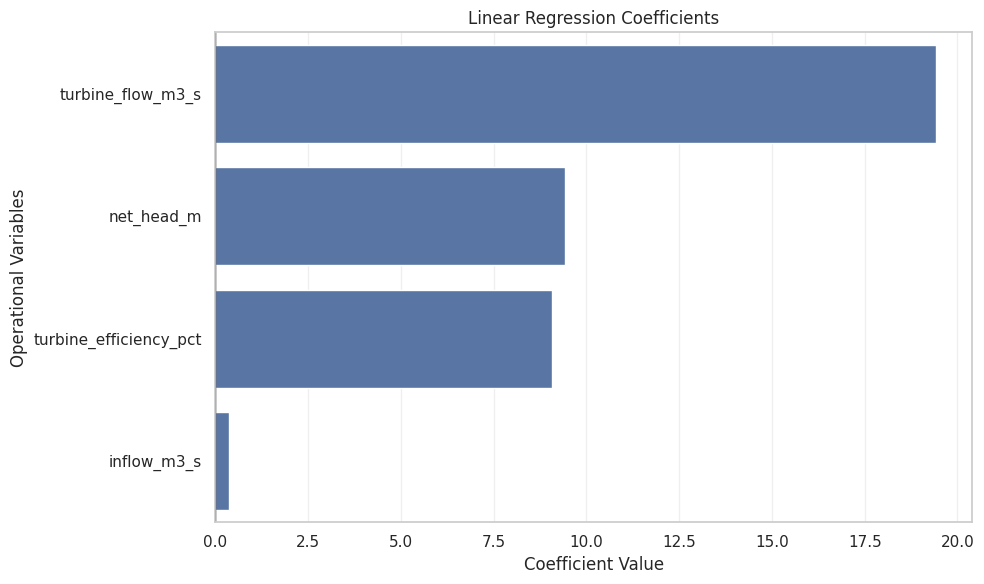

In [29]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=coefficients,
    x='Coefficient',
    y='Feature'
)

plt.title('Linear Regression Coefficients')
plt.xlabel('Coefficient Value')
plt.ylabel('Operational Variables')
plt.axvline(x=0, color='black', linewidth=1)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

The regression coefficients are positive, with turbine flow having the largest coefficient. Their interpretation requires caution due to differences in measurement units and possible multicollinearity.

## Step 13: Multicollinearity Analysis

The objective of this stage is to investigate multicollinearity between water inflow and turbine flow, which showed a strong correlation in the previous analysis.

The Variance Inflation Factor (VIF) will be used to assess how strongly these two variables are linearly related to each other.

The results will help determine whether multicollinearity may affect the interpretation and stability of the Linear Regression coefficients.

In [30]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Select the two highly correlated features
vif_data = df_clean[
    ['inflow_m3_s', 'turbine_flow_m3_s']
].copy()

# Calculate VIF for each feature
vif_results = pd.DataFrame()

vif_results['Feature'] = vif_data.columns
vif_results['VIF'] = [
    variance_inflation_factor(vif_data.values, i)
    for i in range(vif_data.shape[1])
]

# Display results
display(vif_results.round(2))

,Feature,VIF
0,inflow_m3_s,11.41
1,turbine_flow_m3_s,11.41


## Step 14: Comparing Regression Models to Address Multicollinearity

### Objective

The purpose of this experiment is to investigate whether removing one of the highly correlated variables (water inflow) improves the stability and interpretability of the Linear Regression model.

We will train a second model using turbine flow, net head, and turbine efficiency as input features, while keeping the same training and testing datasets.

The performance of the new model will be compared with the original model using MAE, RMSE, and R².

This comparison will help determine whether removing one highly correlated feature affects predictive accuracy.

In [31]:
# Select features without water inflow
X_train_reduced = X_train[
    ['turbine_flow_m3_s', 'net_head_m', 'turbine_efficiency_pct']
]

X_test_reduced = X_test[
    ['turbine_flow_m3_s', 'net_head_m', 'turbine_efficiency_pct']
]

# Initialize and train the second model
model_reduced = LinearRegression()

model_reduced.fit(X_train_reduced, y_train)

# Generate predictions
y_pred_reduced = model_reduced.predict(X_test_reduced)

print("Second Linear Regression model trained successfully!")

Second Linear Regression model trained successfully!


In [32]:
# Calculate evaluation metrics for the reduced model
mae_reduced = mean_absolute_error(y_test, y_pred_reduced)

rmse_reduced = np.sqrt(
    mean_squared_error(y_test, y_pred_reduced)
)

r2_reduced = r2_score(y_test, y_pred_reduced)

# Display results
print("Reduced Linear Regression Model Evaluation")
print("------------------------------------------")
print(f"MAE: {mae_reduced:.2f} MWh")
print(f"RMSE: {rmse_reduced:.2f} MWh")
print(f"R-squared (R²): {r2_reduced:.4f}")

Reduced Linear Regression Model Evaluation
------------------------------------------
MAE: 9.70 MWh
RMSE: 11.52 MWh
R-squared (R²): 0.9910


In [33]:
model_comparison = pd.DataFrame({
    'Metric': ['MAE (MWh)', 'RMSE (MWh)', 'R²'],
    'Original Model': [mae, rmse, r2],
    'Reduced Model': [mae_reduced, rmse_reduced, r2_reduced]
})

display(model_comparison.round(4))

,Metric,Original Model,Reduced Model
0,MAE (MWh),9.76,9.70
1,RMSE (MWh),11.59,11.52
2,R²,0.99,0.99


### Step 14: Model Comparison – Preliminary Findings

The reduced Linear Regression model, which excludes water inflow, achieved slightly better evaluation results than the original model.

MAE decreased from 9.76 to 9.70 MWh, while RMSE decreased from 11.59 to 11.52 MWh. The R² score increased slightly from 0.9909 to 0.9910.

These results indicate that removing water inflow did not reduce the predictive performance of the model on the testing dataset. The reduced model provides a more compact alternative while maintaining comparable predictive accuracy.

Further validation on additional data would be necessary to confirm whether this improvement is consistent across different periods.

## Step 15: Hydropower Production Scenario Analysis

The objective of this analysis is to explore how changes in operational conditions affect predicted hydropower production.

Using the reduced Linear Regression model, we will examine several hypothetical scenarios involving turbine flow, net head, and turbine efficiency.

The results will help illustrate how different operating conditions may influence electricity generation.

In [34]:
# Create a baseline scenario using average operational values
baseline = pd.DataFrame([{
    'turbine_flow_m3_s': X_train_reduced['turbine_flow_m3_s'].mean(),
    'net_head_m': X_train_reduced['net_head_m'].mean(),
    'turbine_efficiency_pct': X_train_reduced['turbine_efficiency_pct'].mean()
}])

# Create hypothetical scenarios
scenarios = pd.concat([
    baseline.assign(Scenario='Baseline'),

    baseline.assign(
        turbine_flow_m3_s=baseline['turbine_flow_m3_s'] * 1.05,
        Scenario='Turbine Flow +5%'
    ),

    baseline.assign(
        net_head_m=baseline['net_head_m'] * 1.05,
        Scenario='Net Head +5%'
    ),

    baseline.assign(
        turbine_efficiency_pct=baseline['turbine_efficiency_pct'] * 1.02,
        Scenario='Efficiency +2%'
    )
], ignore_index=True)

# Generate production predictions
feature_columns = [
    'turbine_flow_m3_s',
    'net_head_m',
    'turbine_efficiency_pct'
]

scenarios['Predicted Production (MWh)'] = model_reduced.predict(
    scenarios[feature_columns]
)

# Calculate difference from baseline
baseline_prediction = scenarios.loc[
    scenarios['Scenario'] == 'Baseline',
    'Predicted Production (MWh)'
].iloc[0]

scenarios['Change from Baseline (MWh)'] = (
    scenarios['Predicted Production (MWh)'] - baseline_prediction
)

# Display results
display(
    scenarios[
        ['Scenario', 'Predicted Production (MWh)',
         'Change from Baseline (MWh)']
    ].round(2)
)

,Scenario,Predicted Production (MWh),Change from Baseline (MWh)
0,Baseline,849.83,0.00
1,Turbine Flow +5%,892.55,42.72
2,Net Head +5%,893.27,43.44
3,Efficiency +2%,866.48,16.65


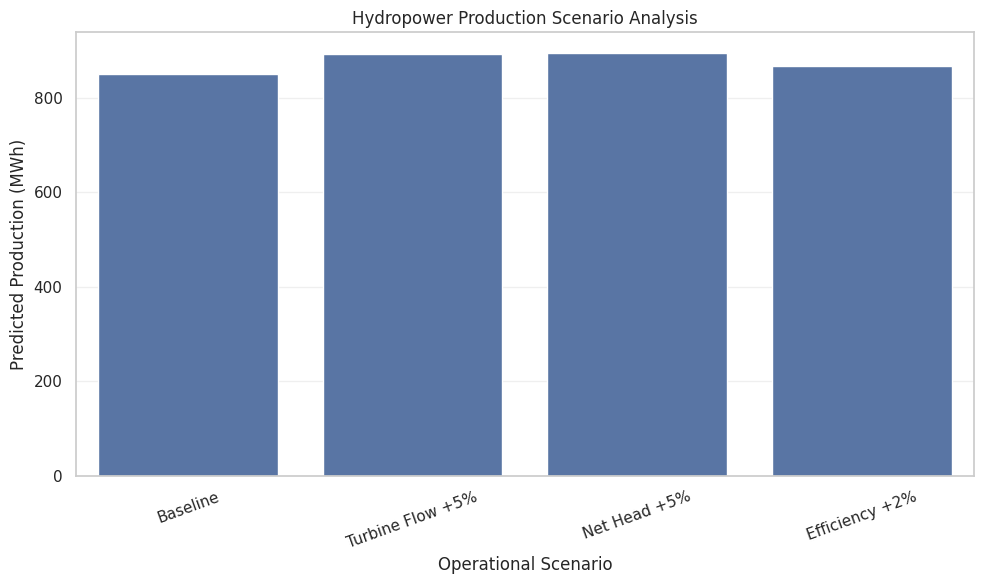

In [35]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=scenarios,
    x='Scenario',
    y='Predicted Production (MWh)'
)

plt.title('Hydropower Production Scenario Analysis')
plt.xlabel('Operational Scenario')
plt.ylabel('Predicted Production (MWh)')
plt.xticks(rotation=20)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


### Scenario Analysis – Key Observations

The scenario analysis shows that all three operational changes result in higher predicted electricity production compared with the baseline scenario.

A 5% increase in net head produces the largest estimated improvement (+43.44 MWh), closely followed by a 5% increase in turbine flow (+42.72 MWh). A 2% increase in turbine efficiency results in an estimated increase of 16.65 MWh.

These results illustrate how changes in operational parameters may affect predicted hydropower production under the assumptions of the Linear Regression model.